# 02. Preparação do Dataset — Pipeline Core (Jane Street)
### Pré-processamento, Divisão Temporal (70/15/15), Seleção de *Features* e Padronização

Este notebook executa a preparação única e reprodutível dos dados que serão consumidos por todos os notebooks de modelagem e ablação (`GRU`, `LSTM`, `CNN–LSTM`, `LSTM + Attention` e blocos A–E), fundamentado nas evidências da EDA (`01_eda.ipynb`):

1. **Ingestão Otimizada e Cache Local:** Cópia dos `.parquet` brutos para `/content/raw_cache` (evitando gargalo de I/O do Google Drive) e filtro do período estável (`date_id >= 700`).
2. **Divisão Temporal Estrita (70% Treino / 15% Validação / 15% Teste):** Separação estritamente cronológica por `date_id` (proibido *split* aleatório devido aos *regime shifts* de volatilidade identificados na Seção 7 da EDA).
3. **Seleção de *Features*:** Ranking das Top 40 *features* via `RandomForestRegressor` ajustado **exclusivamente no conjunto de Treino (70%)**, podando a multicolinearidade identificada na Seção 6 da EDA.
4. **Padronização e Imputação Neutra:** `StandardScaler` ajustado via `partial_fit` exclusivamente no Treino (70%) e transformado coluna a coluna em `float32`, seguido de `NaN = 0.0`, processando um *split* por vez para evitar OOM no Colab.
5. **Persistência e Auditoria:** Exportação de `train.parquet`, `val.parquet`, `test.parquet`, `selected_features.json`, `feature_importance.csv` em `data/processed/` e do `scaler` em `models/`.

---
## 1. Importação de Bibliotecas e Configuração do Ambiente

Configuramos as bibliotecas, a semente aleatória global (`SEED = 42`), a integração automática com o Google Drive no Colab e os hiperparâmetros estruturais do pipeline **Core**.

In [1]:
# 1.1 Importação de bibliotecas e configuração visual
import os
import gc
import sys
import glob
import json
import shutil
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor

SEED = 42
np.random.seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

In [2]:
# 1.2 Suporte automático para execução no Google Colab e estrutura de diretórios
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    print("[*] Google Colab detectado! Montando Google Drive...")
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = '/content/drive/MyDrive/ProjetosRedesNeurais/Unidade3'
    if os.path.exists(PROJECT_ROOT):
        os.chdir(PROJECT_ROOT)
        print(f"[*] Diretório de trabalho: {os.getcwd()}")
    else:
        raise FileNotFoundError(f"Diretório não encontrado no Drive: {PROJECT_ROOT}")
else:
    print("[*] Ambiente Local detectado!")

DATA_DIR = "data"
PROCESSED_DIR = os.path.join(DATA_DIR, "processed")
MODELS_DIR = "models"
GRAPHS_DIR = "graphs"
PREFIXO = "core"

os.makedirs(PROCESSED_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(GRAPHS_DIR, exist_ok=True)

Mounted at /content/drive
[*] Diretório de trabalho: /content/drive/MyDrive/ProjetosRedesNeurais/Unidade3


In [3]:
# 1.3 Parâmetros globais do Core
DATE_MIN = 700
TOP_K = 40
TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

TARGET_COL = "responder_6"

# Mantemos alvos auxiliares correlacionados (EDA Seção 4) para viabilizar o Bloco D (Multi-Task) sem reprocessar os brutos
AUX_TARGETS = ["responder_3", "responder_7", "responder_8"]
FEATURE_COLS = [f"feature_{i:02d}" for i in range(79)]
META_COLS = ["date_id", "time_id", "symbol_id", "weight", TARGET_COL] + AUX_TARGETS

assert abs((TRAIN_RATIO + VAL_RATIO + TEST_RATIO) - 1.0) < 1e-9, "As proporções devem somar 1.0"
print(f"[*] Configuração Core: date_id >= {DATE_MIN} | Split {int(TRAIN_RATIO*100)}/{int(VAL_RATIO*100)}/{int(TEST_RATIO*100)} | Top {TOP_K} features")

[*] Configuração Core: date_id >= 700 | Split 70/15/15 | Top 40 features


---
## 2. Cache Local (`/content`) e Mapeamento Temporal

Para evitar gargalo de I/O na leitura do Google Drive, copiamos os arquivos `.parquet` brutos para o disco SSD local (`/content/raw_cache`) quando em Colab (pulando arquivos já copiados na mesma sessão). Em seguida, fazemos uma **passagem leve** lendo apenas `date_id` para listar todos os dias do período estável sem sobrecarregar a RAM.

In [4]:
# 2.1 Descoberta segura dos parquets brutos e cópia para cache local no Colab
arquivos_drive = sorted([
    f for f in glob.glob(os.path.join(DATA_DIR, "**", "*.parquet"), recursive=True)
    if os.path.isfile(f) and "lags" not in os.path.basename(f).lower() and "processed" not in f
])
assert len(arquivos_drive) > 0, f"Nenhum arquivo .parquet encontrado em {DATA_DIR}/"

if IN_COLAB:
    LOCAL_RAW_DIR = "/content/raw_cache"
    os.makedirs(LOCAL_RAW_DIR, exist_ok=True)
    arquivos = []
    for i, src in enumerate(arquivos_drive, start=1):
        rel = os.path.relpath(src, DATA_DIR)
        dst = os.path.join(LOCAL_RAW_DIR, rel)
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        if not os.path.exists(dst):
            print(f"[*] Copiando ({i}/{len(arquivos_drive)}): {rel}")
            shutil.copy2(src, dst)
        arquivos.append(dst)
    print(f"[*] Cache local pronto em {LOCAL_RAW_DIR}: {len(arquivos)} arquivo(s).")
else:
    arquivos = arquivos_drive
    print(f"[*] Arquivos parquet encontrados: {len(arquivos)}")

[*] Copiando (1/10): raw/train.parquet/partition_id=0/part-0.parquet
[*] Copiando (2/10): raw/train.parquet/partition_id=1/part-1.parquet
[*] Copiando (3/10): raw/train.parquet/partition_id=2/part-2.parquet
[*] Copiando (4/10): raw/train.parquet/partition_id=3/part-3.parquet
[*] Copiando (5/10): raw/train.parquet/partition_id=4/part-4.parquet
[*] Copiando (6/10): raw/train.parquet/partition_id=5/part-5.parquet
[*] Copiando (7/10): raw/train.parquet/partition_id=6/part-6.parquet
[*] Copiando (8/10): raw/train.parquet/partition_id=7/part-7.parquet
[*] Copiando (9/10): raw/train.parquet/partition_id=8/part-8.parquet
[*] Copiando (10/10): raw/train.parquet/partition_id=9/part-9.parquet
[*] Cache local pronto em /content/raw_cache: 10 arquivo(s).


In [5]:
# 2.2 Passagem leve: lê apenas a coluna date_id para mapear os pregões disponíveis
dias_set = set()
for arq in arquivos:
    d_part = pd.read_parquet(arq, columns=["date_id"])
    d_part = d_part[d_part["date_id"] >= DATE_MIN]
    dias_set.update(d_part["date_id"].unique().tolist())

dias = np.sort(np.array(list(dias_set), dtype=np.int32))
print(f"[*] Total de dias estáveis (date_id >= {DATE_MIN}): {len(dias)} (de {dias[0]} até {dias[-1]})")

[*] Total de dias estáveis (date_id >= 700): 999 (de 700 até 1698)


---
## 3. Divisão Temporal (70% Treino / 15% Validação / 15% Teste)

Conforme comprovado pela análise de *Regime Shift* na Seção 7 da EDA (`01_eda.ipynb`), a volatilidade apresenta forte agrupamento temporal (*volatility clustering*). Por isso, é **estritamente proibido** utilizar *split* aleatório: dividimos os `date_id`s em ordem estritamente cronológica:

- **Treino (70%):** ajuste da seleção de *features*, ajuste do `StandardScaler` e treinamento das redes neurais.
- **Validação (15%):** seleção de hiperparâmetros, *Early Stopping*, `ReduceLROnPlateau` e comparação entre arquiteturas/ablações.
- **Teste (15%):** conjunto final intocado (*holdout* futuro) para avaliação definitiva de generalização.

,Conjunto,date_id Início,date_id Fim,Dias,Proporção (%)
0,Treino (70%),700,1398,699,69.97
1,Validação (15%),1399,1547,149,14.91
2,Teste (15%),1548,1698,151,15.12


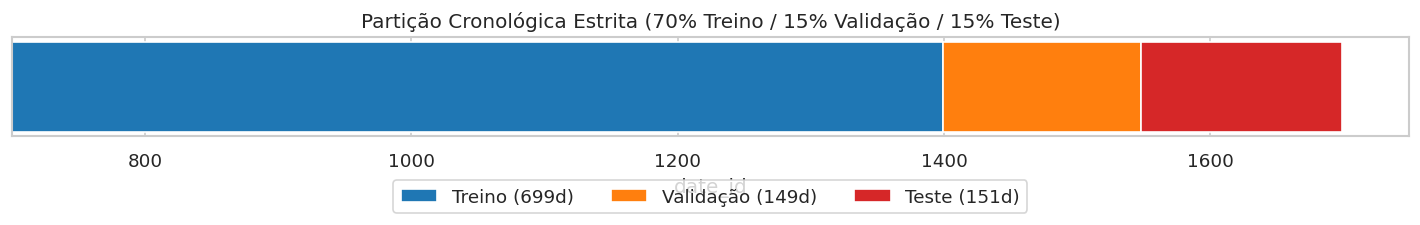

In [6]:
# 3.1 Cálculo dos cortes cronológicos (70% / 15% / 15%) por date_id
n_dias = len(dias)
idx_train_end = int(np.floor(n_dias * TRAIN_RATIO))
idx_val_end = idx_train_end + int(np.floor(n_dias * VAL_RATIO))

train_days = dias[:idx_train_end]
val_days = dias[idx_train_end:idx_val_end]
test_days = dias[idx_val_end:]

# Verificação estrita de ordenação e ausência de sobreposição (Zero Leakage)
assert len(set(train_days) & set(val_days)) == 0, "Sobreposição entre Treino e Validação!"
assert len(set(train_days) & set(test_days)) == 0, "Sobreposição entre Treino e Teste!"
assert len(set(val_days) & set(test_days)) == 0, "Sobreposição entre Validação e Teste!"
assert train_days[-1] < val_days[0] and val_days[-1] < test_days[0], "Ordem cronológica violada!"

resumo_splits = pd.DataFrame([
    {"Conjunto": "Treino (70%)", "date_id Início": int(train_days[0]), "date_id Fim": int(train_days[-1]), "Dias": len(train_days), "Proporção (%)": round(len(train_days) / n_dias * 100, 2)},
    {"Conjunto": "Validação (15%)", "date_id Início": int(val_days[0]), "date_id Fim": int(val_days[-1]), "Dias": len(val_days), "Proporção (%)": round(len(val_days) / n_dias * 100, 2)},
    {"Conjunto": "Teste (15%)", "date_id Início": int(test_days[0]), "date_id Fim": int(test_days[-1]), "Dias": len(test_days), "Proporção (%)": round(len(test_days) / n_dias * 100, 2)},
])
display(resumo_splits)

# Visualização da partição temporal
fig, ax = plt.subplots(figsize=(12, 2.4))
ax.barh([0], [len(train_days)], left=train_days[0], color="#1f77b4", height=0.5, label=f"Treino ({len(train_days)}d)")
ax.barh([0], [len(val_days)], left=val_days[0], color="#ff7f0e", height=0.5, label=f"Validação ({len(val_days)}d)")
ax.barh([0], [len(test_days)], left=test_days[0], color="#d62728", height=0.5, label=f"Teste ({len(test_days)}d)")
ax.set_yticks([])
ax.set_xlabel("date_id")
ax.set_title("Partição Cronológica Estrita (70% Treino / 15% Validação / 15% Teste)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.35), ncol=3, frameon=True)
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, f"{PREFIXO}_splits_temporais.png"), dpi=200, bbox_inches="tight")
plt.show()

---
## 4. Seleção de *Features* Sem Vazamento (Top 40 via Random Forest)

Na Seção 6 da EDA verificamos que as correlações lineares individuais com `responder_6` são inferiores a `0.05` e que existem blocos de alta colinearidade entre variáveis. Por isso, aplicamos um método **não linear** (`RandomForestRegressor`) sobre uma amostra sistemática de até **250.000 registros extraídos exclusivamente do conjunto de Treino (70%)**, garantindo **zero vazamento** da Validação e do Teste.

In [7]:
# 4.1 Amostragem sistemática das 79 features estritamente dentro do Treino (70%)
AMOSTRA_RF = 250_000
amostra_por_arq = max(1, AMOSTRA_RF // max(1, len(arquivos)))
train_days_set = set(train_days.tolist())

dfs_rf = []
for arq in arquivos:
    part = pd.read_parquet(arq, columns=["date_id", "weight", TARGET_COL] + FEATURE_COLS)
    part = part[(part["date_id"].isin(train_days_set)) & (part["weight"] > 0)]
    if len(part) > 0:
        if len(part) > amostra_por_arq:
            idx = np.linspace(0, len(part) - 1, amostra_por_arq, dtype=int)
            part = part.iloc[idx]
        dfs_rf.append(part)

df_rf = pd.concat(dfs_rf, ignore_index=True)
del dfs_rf
gc.collect()

if len(df_rf) > AMOSTRA_RF:
    idx = np.linspace(0, len(df_rf) - 1, AMOSTRA_RF, dtype=int)
    df_rf = df_rf.iloc[idx]

X_ref = df_rf[FEATURE_COLS].fillna(0.0).astype("float32").values
y_ref = df_rf[TARGET_COL].astype("float32").values
w_ref = df_rf["weight"].astype("float32").values
del df_rf
gc.collect()

print(f"[*] Amostra de treino para Feature Selection: {X_ref.shape}")

[*] Amostra de treino para Feature Selection: (125000, 79)


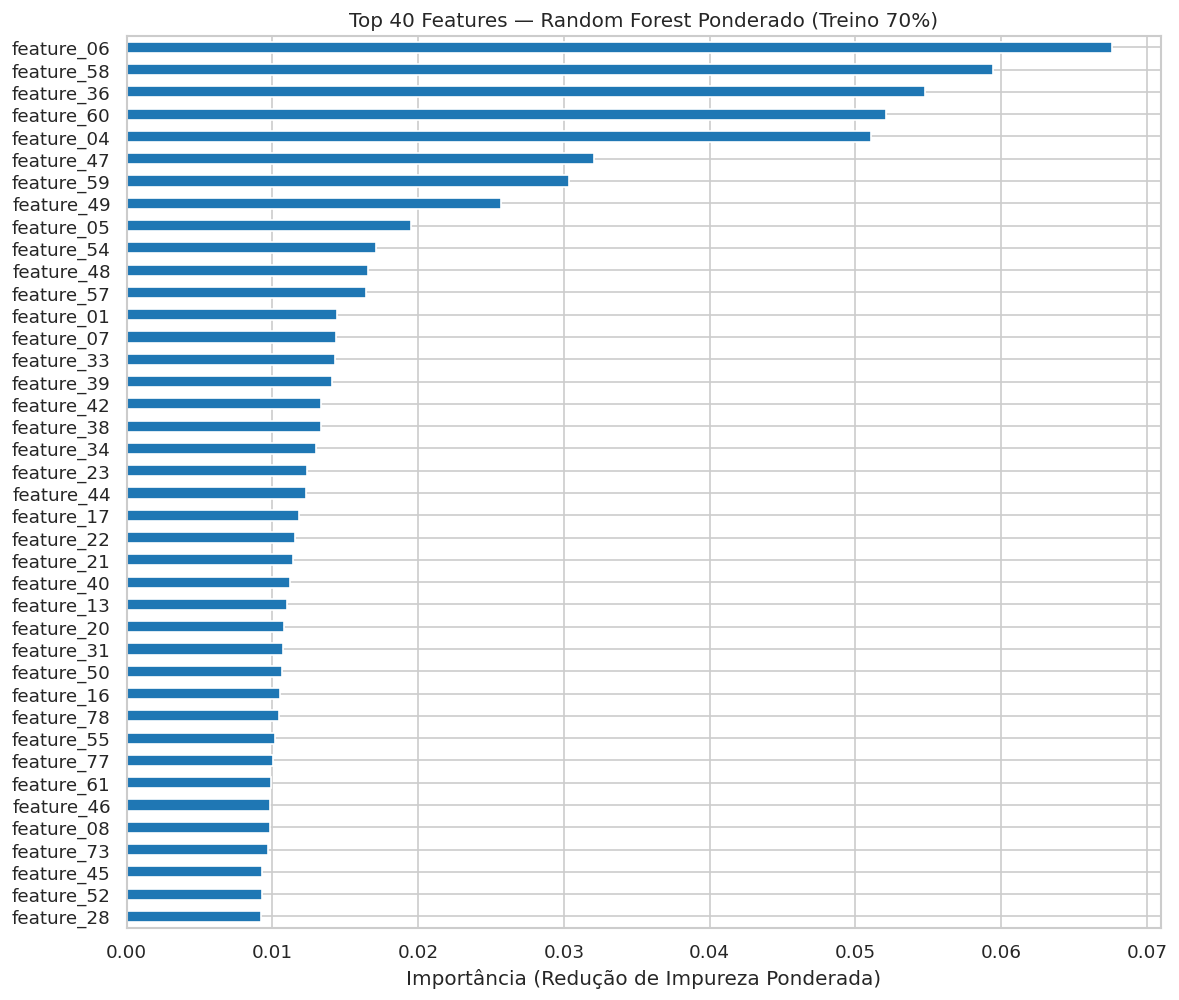

,Importância
feature_06,0.06758
feature_58,0.05945
feature_36,0.05479
feature_60,0.05208
feature_04,0.05107
feature_47,0.03208
feature_59,0.03032
feature_49,0.02566
feature_05,0.01952
feature_54,0.01711


[*] 40 features salvas em data/processed/selected_features.json


In [8]:
# 4.2 Ajuste do RandomForestRegressor (ponderado por weight) e exportação das Top 40 features
rf = RandomForestRegressor(n_estimators=50, max_depth=8, n_jobs=-1, random_state=SEED)
rf.fit(X_ref, y_ref, sample_weight=w_ref)
del X_ref, y_ref, w_ref
gc.collect()

importancias = pd.Series(rf.feature_importances_, index=FEATURE_COLS).sort_values(ascending=False)
SELECTED_COLS = importancias.head(TOP_K).index.tolist()

# Persistência do ranking completo e da lista selecionada
importancias.to_csv(os.path.join(PROCESSED_DIR, "feature_importance.csv"), header=["importance"])
with open(os.path.join(PROCESSED_DIR, "selected_features.json"), "w") as f:
    json.dump(SELECTED_COLS, f, indent=2)

# Visualização do Top K
plt.figure(figsize=(10, 8.5))
importancias.head(TOP_K).sort_values().plot(kind="barh", color="#1f77b4")
plt.title(f"Top {TOP_K} Features — Random Forest Ponderado (Treino 70%)")
plt.xlabel("Importância (Redução de Impureza Ponderada)")
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, f"{PREFIXO}_feature_importance_top{TOP_K}.png"), dpi=200, bbox_inches="tight")
plt.show()

display(importancias.head(10).to_frame(name="Importância").round(5))
print(f"[*] {len(SELECTED_COLS)} features salvas em {PROCESSED_DIR}/selected_features.json")

---
## 5. Carregamento Otimizado, Padronização Sem Vazamento e Exportação

Para evitar estouro de RAM (OOM) no Google Colab:
1. Carregamos **um *split* por vez** (`train`, depois `val`, depois `test`), lendo apenas as colunas necessárias (`META_COLS + SELECTED_COLS`, convertidas para `float32`/`int32`) e ordenando por `["symbol_id", "date_id", "time_id"]`.
2. Ajustamos o `StandardScaler` exclusivamente sobre o **Treino (70%)** usando `partial_fit` em blocos de 500 mil linhas (evitando cópias gigantes em `float64`).
3. Aplicamos a padronização **coluna a coluna em `float32`** seguida da imputação neutra (`NaN = 0.0`, conforme Seção 5 da EDA), salvando o `scaler` em `models/core_scaler.joblib` e cada conjunto pronto em `data/processed/`.

In [9]:
# 5.1 Funções auxiliares de leitura por split e transformação segura em memória
COLS_NEEDED = META_COLS + SELECTED_COLS
FLOAT_COLS = SELECTED_COLS + ["weight", TARGET_COL] + AUX_TARGETS
INT_COLS = ["date_id", "time_id", "symbol_id"]

def carregar_split(days_array):
    days_set = set(days_array.tolist())
    partes = []

    for arq in arquivos:
        part = pd.read_parquet(arq, columns=COLS_NEEDED)
        part = part[part["date_id"].isin(days_set)]
        if len(part) > 0:
            for c in FLOAT_COLS:
                part[c] = part[c].astype("float32")
            for c in INT_COLS:
                part[c] = part[c].astype("int32")
            partes.append(part)

    df_split = pd.concat(partes, ignore_index=True)
    del partes
    gc.collect()

    df_split = df_split.sort_values(["symbol_id", "date_id", "time_id"]).reset_index(drop=True)

    return df_split

def aplicar_scaler_e_imputar_inplace(df_split, scaler, feature_cols):
    means = scaler.mean_.astype(np.float32)
    scales = scaler.scale_.astype(np.float32)

    for j, col in enumerate(feature_cols):
        vals = df_split[col].to_numpy(dtype=np.float32, copy=True)
        vals = (vals - means[j]) / (scales[j] if scales[j] != 0.0 else np.float32(1.0))
        np.nan_to_num(vals, copy=False, nan=0.0, posinf=0.0, neginf=0.0)
        df_split[col] = vals

    return df_split

In [10]:
# 5.2 Ajuste do StandardScaler no Treino (70%) e exportação sequencial de train, val e test
# --- TREINO (70%) ---
print("[*] Processando TREINO (70%)...")

tr_df = carregar_split(train_days)
scaler = StandardScaler()

CHUNK = 500_000
for ini in range(0, len(tr_df), CHUNK):
    scaler.partial_fit(tr_df[SELECTED_COLS].iloc[ini : ini + CHUNK])

joblib.dump(scaler, os.path.join(MODELS_DIR, f"{PREFIXO}_scaler.joblib"))
aplicar_scaler_e_imputar_inplace(tr_df, scaler, SELECTED_COLS)
tr_df.to_parquet(os.path.join(PROCESSED_DIR, "train.parquet"), index=False)

print(f"[*] train.parquet salvo: {tr_df.shape}")

del tr_df
gc.collect()

# --- VALIDAÇÃO (15%) ---
print("[*] Processando VALIDAÇÃO (15%)...")

va_df = carregar_split(val_days)
aplicar_scaler_e_imputar_inplace(va_df, scaler, SELECTED_COLS)
va_df.to_parquet(os.path.join(PROCESSED_DIR, "val.parquet"), index=False)

print(f"[*] val.parquet salvo: {va_df.shape}")

del va_df
gc.collect()

# --- TESTE (15%) ---
print("[*] Processando TESTE (15%)...")

te_df = carregar_split(test_days)
aplicar_scaler_e_imputar_inplace(te_df, scaler, SELECTED_COLS)
te_df.to_parquet(os.path.join(PROCESSED_DIR, "test.parquet"), index=False)

print(f"[*] test.parquet salvo: {te_df.shape}")

del te_df
gc.collect()

[*] Processando TREINO (70%)...
[*] train.parquet salvo: (23736328, 48)
[*] Processando VALIDAÇÃO (15%)...
[*] val.parquet salvo: (5418864, 48)
[*] Processando TESTE (15%)...
[*] test.parquet salvo: (5609560, 48)


0

---
## 6. Auditoria e Validação dos Artefatos Gerados

Validamos a integridade dos conjuntos salvos em `data/processed/` conferindo:
- Contagem de registros, dias únicos e tamanho em disco (`MB`);
- Ausência total de `NaN`s nas 40 *features* selecionadas;
- Ordem cronológica estrita (`train_max < val_min` e `val_max < test_min`);
- Padronização correta no treino (média próxima de `0.0` e desvio padrão próximo de `1.0`).

In [11]:
# 6.1 Auditoria dos arquivos processados
auditoria = []
limites = {}

for nome in ["train", "val", "test"]:
    caminho = os.path.join(PROCESSED_DIR, f"{nome}.parquet")
    tamanho_mb = os.path.getsize(caminho) / (1024 ** 2)
    df_chk = pd.read_parquet(caminho, columns=["date_id", TARGET_COL] + SELECTED_COLS[:5])

    d_min, d_max = int(df_chk["date_id"].min()), int(df_chk["date_id"].max())
    limites[nome] = (d_min, d_max)
    nans_amostra = int(df_chk[SELECTED_COLS[:5]].isna().sum().sum())
    media_f0 = float(df_chk[SELECTED_COLS[0]].mean())
    std_f0 = float(df_chk[SELECTED_COLS[0]].std())

    auditoria.append({
        "Arquivo": f"{nome}.parquet",
        "Linhas": f"{len(df_chk):,}",
        "date_id": f"{d_min} – {d_max}",
        "Dias": int(df_chk["date_id"].nunique()),
        "Tamanho (MB)": round(tamanho_mb, 1),
        "NaNs (Top 5 feats)": nans_amostra,
        f"Média ({SELECTED_COLS[0]})": round(media_f0, 4),
        f"Std ({SELECTED_COLS[0]})": round(std_f0, 4),
    })
    del df_chk
    gc.collect()

assert limites["train"][1] < limites["val"][0], "Vazamento temporal entre train e val!"
assert limites["val"][1] < limites["test"][0], "Vazamento temporal entre val e test!"

display(pd.DataFrame(auditoria))
print("[*] Auditoria concluída sem vazamento temporal e sem NaNs!")

,Arquivo,Linhas,date_id,Dias,Tamanho (MB),NaNs (Top 5 feats),Média (feature_06),Std (feature_06)
0,train.parquet,"23,736,328",700 – 1398,699,3801.4,0,-0.0000,0.9704
1,val.parquet,"5,418,864",1399 – 1547,149,875.4,0,0.0019,1.0360
2,test.parquet,"5,609,560",1548 – 1698,151,909.3,0,0.0012,0.9302


[*] Auditoria concluída sem vazamento temporal e sem NaNs!


---
## 7. Síntese dos Artefatos Gerados

| Artefato | Localização | Uso nos Próximos Notebooks |
| :--- | :--- | :--- |
| `train.parquet` (70%) | `data/processed/train.parquet` | Treinamento do Core e de todas as arquiteturas/ablações |
| `val.parquet` (15%) | `data/processed/val.parquet` | *Early Stopping*, `ReduceLROnPlateau` e seleção de modelos |
| `test.parquet` (15%) | `data/processed/test.parquet` | Avaliação final intocada (*Weighted $R^2$*, RMSE, MAE e XAI) |
| `selected_features.json` | `data/processed/selected_features.json` | Lista padronizada das Top 40 *features* |
| `feature_importance.csv` | `data/processed/feature_importance.csv` | Ranking completo das 79 *features* (Treino 70%) |
| `core_scaler.joblib` | `models/core_scaler.joblib` | `StandardScaler` ajustado exclusivamente no Treino |
| `core_splits_temporais.png` | `graphs/core_splits_temporais.png` | Figura da partição temporal 70/15/15 para o artigo |
| `core_feature_importance_top40.png` | `graphs/core_feature_importance_top40.png` | Figura do ranking de *Feature Importance* para o artigo |